In [3]:
import cv2
import matplotlib.pyplot as plt

# Read the Image in

In [4]:
folder = "/Users/wueli/sw_source/dartcv/data/images/single_dart"
file_path_single_dart = folder + "/PXL_20261018_152634348.jpg"

img = cv2.imread(file_path_single_dart, cv2.IMREAD_COLOR)

In [ ]:
def display_image(img, display_width=5):
    height, width = img.shape[:2]
    print(f"Image dimensions: {width} x {height} pixels")
    plt.figure(figsize=(display_width, display_width * height / width))

    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    elif img.ndim == 3 and img.shape[2] == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        raise ValueError(f"Unsupported image shape: {img.shape}")

    plt.axis("off")
    plt.show()
WORK_SIZE = 1000
def resize_image_to_work_size(img):
    s = WORK_SIZE / max(img.shape[:2])
    return (
        cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        if s < 1
        else img
    )

def show_image_grid(
    images,
    titles,
    cmaps=None,
    roi=None,
    max_cols=2,
    panel_size=(10, 5),
):
    if not images:
        raise ValueError("Provide at least one image")
    if len(images) != len(titles):
        raise ValueError("Each image needs a title")

    if cmaps is None:
        cmaps = [None] * len(images)
    if len(cmaps) != len(images):
        raise ValueError("Provide one colormap per image")

    if roi is not None:
        x, y, width, height = map(int, roi)
        image_height, image_width = images[0].shape[:2]
        if x < 0 or y < 0 or width <= 0 or height <= 0:
            raise ValueError("ROI must have positive size and nonnegative coordinates")
        if x + width > image_width or y + height > image_height:
            raise ValueError("ROI must fit inside the images")
        images = [image[y:y + height, x:x + width] for image in images]

    ncols = min(max_cols, len(images))
    nrows = (len(images) + ncols - 1) // ncols
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(panel_size[0] * ncols, panel_size[1] * nrows),
        squeeze=False,
    )

    for axis, image, title, cmap in zip(axes.flat, images, titles, cmaps):
        axis.imshow(image, cmap=cmap)
        axis.set_title(title)
        axis.axis("off")

    for axis in axes.flat[len(images):]:
        axis.set_visible(False)

    fig.tight_layout()
    plt.show()
    return fig, axes



Image dimensions: 753 x 1000 pixels


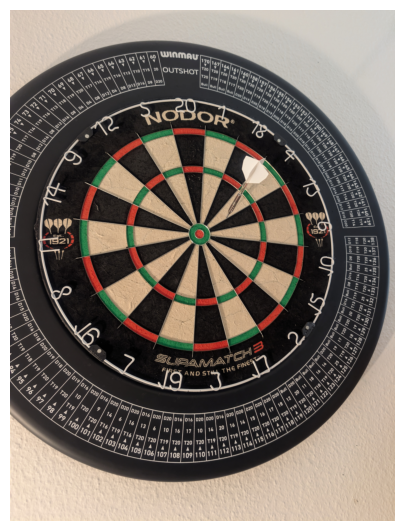

In [8]:
#display_image(img,10)
small = resize_image_to_work_size(img)
display_image(small,5)

- https://stackoverflow.com/questions/47483951/how-can-i-define-a-threshold-value-to-detect-only-green-colour-objects-in-an-ima
- https://docs.opencv.org/4.13.0/d9/d61/tutorial_py_morphological_ops.html



In [9]:
from dartcv.detect import _colour_mask

s = small.shape[1] / img.shape[1]
array = _colour_mask(small)
array.shape

(1000, 753)

In [10]:
import numpy as np


hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hue, saturation, value = hsv[..., 0], hsv[..., 1], hsv[..., 2]
# Heuristic HSV cutoffs for the board's green paint.
green_mask = (hue > 40) & (hue < 90) & (saturation > 90) & (value > 50)
mask = green_mask.astype(np.uint8) * 255
mask_open = cv2.morphologyEx(
    mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)
)
mask_open_close = cv2.morphologyEx(
    mask_open, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8)
)
mask_open_close


array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(8160, 6144), dtype=uint8)

In [37]:
BLACK_VALUE_MAX = 50
WHITE_VALUE_MIN = 210
WHITE_SATURATION_MAX = 50

blackish_mask = value <= BLACK_VALUE_MAX
blackish_mask = blackish_mask.astype(np.uint8) * 255
whitish_mask = (value >= WHITE_VALUE_MIN) & (saturation <= WHITE_SATURATION_MAX)
whitish_mask = whitish_mask.astype(np.uint8) * 255
beige_mask = (
    (hue >= 10) & (hue <= 35)
    & (saturation >= 15) & (saturation <= 110)
    & (value >= 80)
)
beige_mask = beige_mask.astype(np.uint8) * 255
all_mask = blackish_mask | whitish_mask | beige_mask
all_mask = all_mask.astype(np.uint8) * 255

Image dimensions: 6144 x 8160 pixels


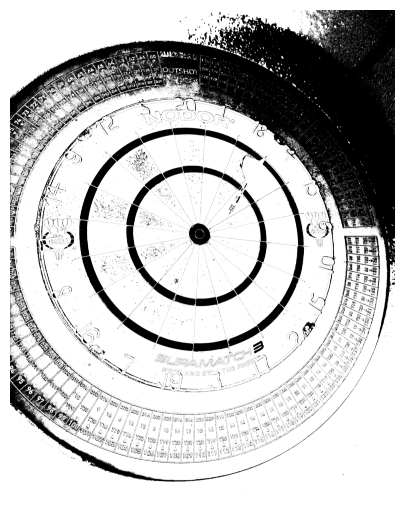

In [40]:
display_image(all_mask)

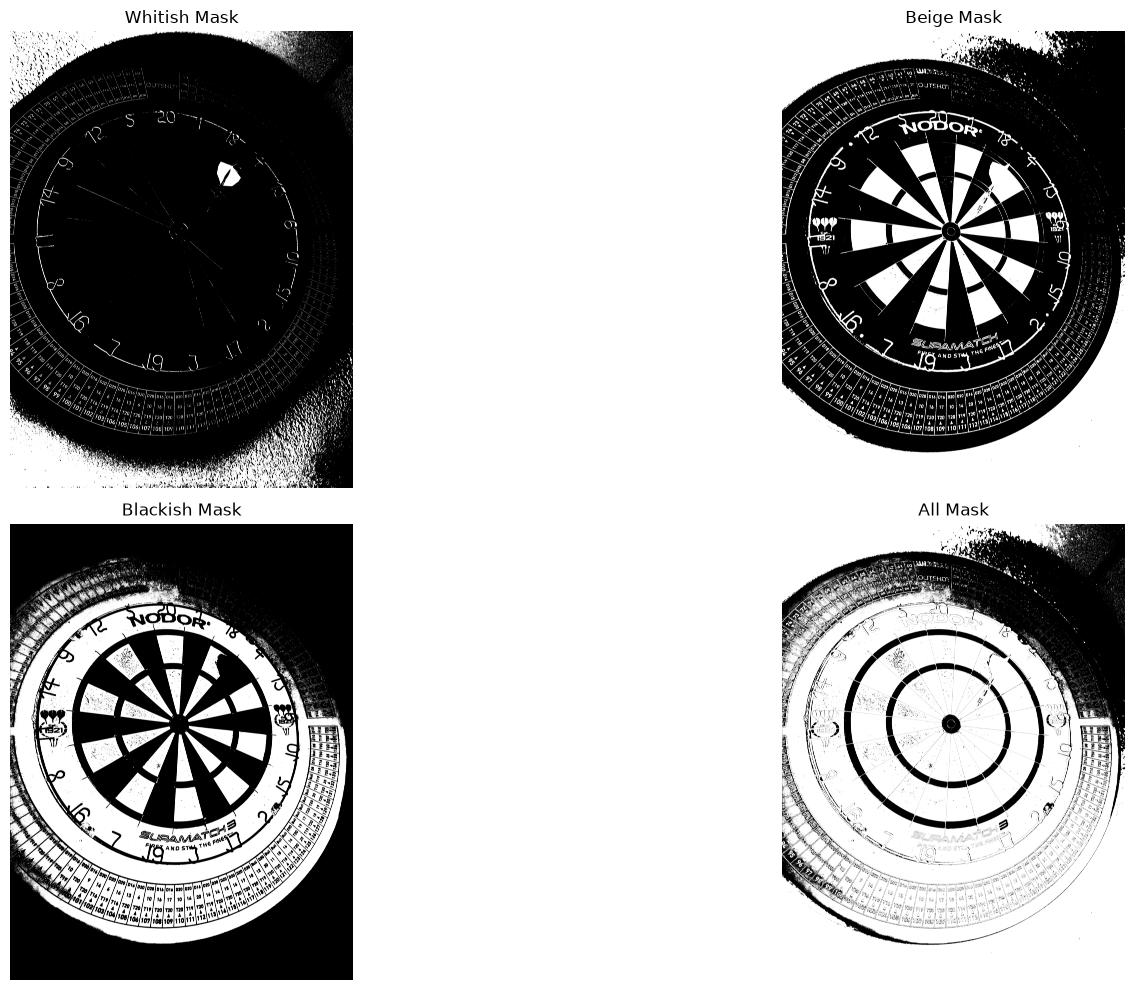

(<Figure size 2000x1000 with 4 Axes>,
 array([[<Axes: title={'center': 'Whitish Mask'}>,
         <Axes: title={'center': 'Beige Mask'}>],
        [<Axes: title={'center': 'Blackish Mask'}>,
         <Axes: title={'center': 'All Mask'}>]], dtype=object))

In [38]:
show_image_grid(
    [whitish_mask, beige_mask, blackish_mask, all_mask], 
    ["Whitish Mask", "Beige Mask", "Blackish Mask", "All Mask"], 
    cmaps=["gray", "gray", "gray", "gray"],
    panel_size=(10,5)
)


In [ ]:
display_image(blackish_mask)

Image dimensions: 753 x 1000 pixels


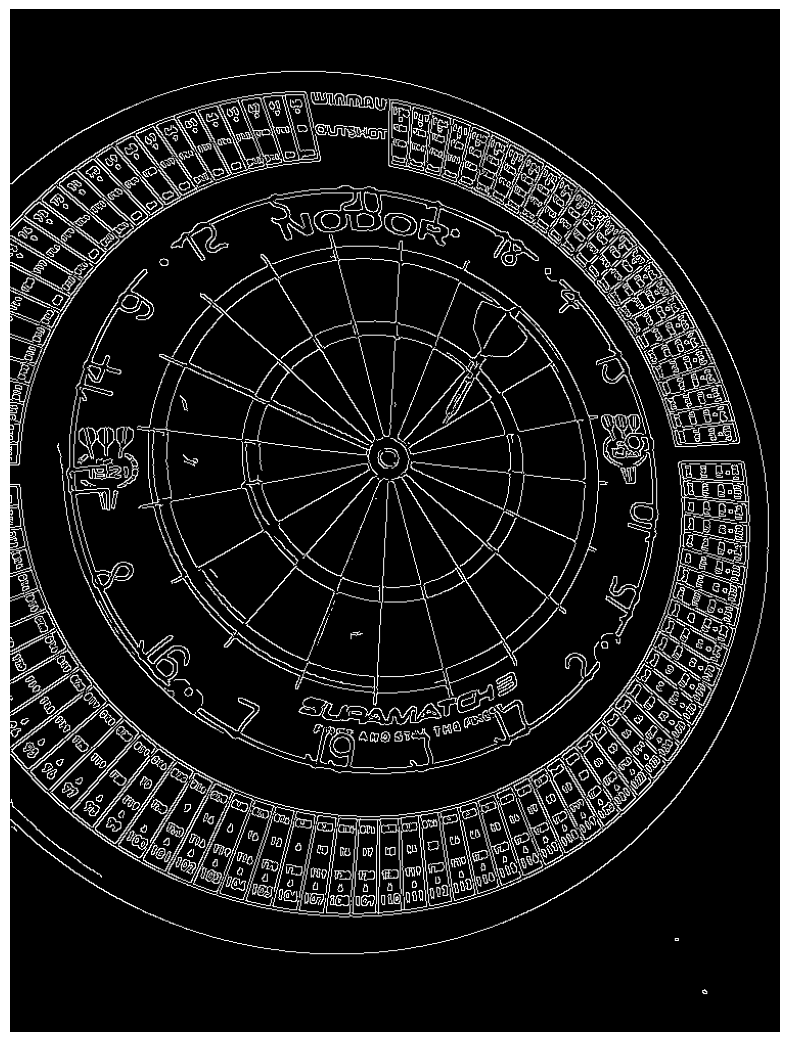

In [41]:
gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blurred, 50, 150)

display_image(edges, display_width=10)

Image dimensions: 6144 x 8160 pixels


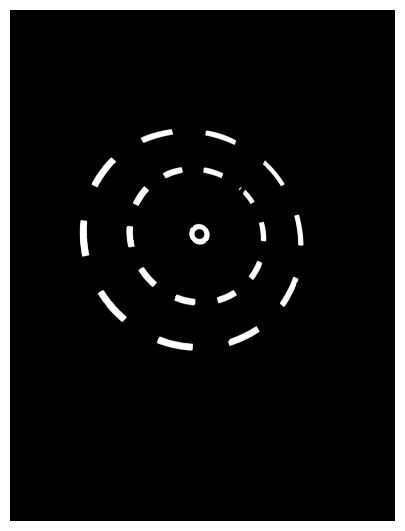

In [16]:
display_image(mask_open_close)


In [ ]:
hsv_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

fig, axes = show_image_grid(
    [hsv_rgb, mask, mask_open_close, mask_open_close - mask],
    ["HSV image", "Green mask", "After opening and closing", "Changed pixels"],
    [None, "gray", "gray", "gray"],
    roi=(3000, 3000, 2000, 2000),
    panel_size=(10, 5),
)

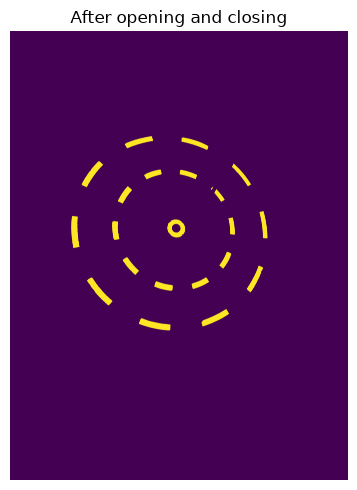

In [15]:
hsv_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)

fig, axes = show_image_grid(
    [mask_open_close],
    titles=["After opening and closing"],
    #roi=(3000, 3000, 2000, 2000),
    panel_size=(10, 5),
)

In [73]:
x, y, width, height = map(int, cv2.selectROI("Select region", img))
cv2.destroyWindow("Select region")

image_crop = img[y:y + height, x:x + width]
mask_crop = mask[y:y + height, x:x + width]

Select a ROI and then press SPACE or ENTER button!
Cancel the selection process by pressing c button!


In [ ]:
import cv2
import numpy as np

# 1. Create a simple binary image (black background)
image = np.zeros((100, 100), dtype=np.uint8)

# Add 3 separate white shapes (value 255)
image[10:30, 10:40] = 255  # Rectangle top-left
image[60:80, 20:40] = 255  # Square bottom-left
image[20:25, 70:75] = 255  # Small square top-right

# 2. Apply connectedComponentsWithStats
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(image, connectivity=8)

# 3. Visualization Setup
# Convert the single-channel binary image to a 3-channel BGR image so we can draw in color
output_image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

# 4. Loop through each component to draw bounding boxes and centroids
for i in range(1, num_labels): # Start at 1 to skip the background (label 0)
    
    # Extract the bounding box coordinates and dimensions
    x = stats[i, cv2.CC_STAT_LEFT]
    y = stats[i, cv2.CC_STAT_TOP]
    w = stats[i, cv2.CC_STAT_WIDTH]
    h = stats[i, cv2.CC_STAT_HEIGHT]
    
    # Extract the centroid
    (cX, cY) = centroids[i]
    
    # Draw a green bounding box around the component
    cv2.rectangle(output_image, (x, y), (x + w, y + h), (0, 255, 0), 1)
    
    # Draw a red circle at the centroid
    cv2.circle(output_image, (int(cX), int(cY)), 1, (0, 0, 255), -1)

# 5. Display the image
# Scale the image up slightly just so it is easier to see on screen
output_image_scaled = cv2.resize(output_image, (400, 400), interpolation=cv2.INTER_NEAREST)

cv2.imshow("Connected Components", output_image_scaled)
cv2.waitKey(0) # Wait indefinitely until a key is pressed
cv2.destroyAllWindows()

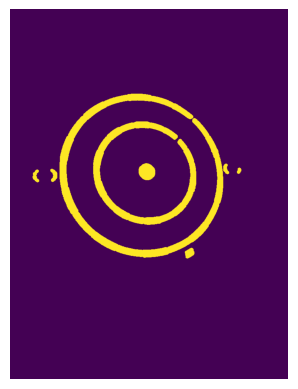

In [30]:
plt.imshow(array)
plt.axis("off")
plt.show()  

In [ ]:
from dartcv.detect import detect_board

board_detection = detect_board(img, diagnostics=True)

## Board detection stages

`detect_board` maps the dartboard model to the source image. The views below use the detector's captured diagnostics, so they show estimates and intermediate evidence rather than ground-truth measurements.

1. **Colour segmentation:** saturated red/green pixels are selected on a reduced working image.
2. **Outer ellipse:** boundary samples are gathered and outliers rejected while fitting the outer double ring.
3. **Bull constraint:** a supported red bull can anchor the model origin while preserving the outer ellipse.
4. **Orientation and initial alignment:** alternating double-ring colours estimate rotation; the result is the seed homography before ECC.
5. **ECC refinement:** board-masked image gradients are aligned to a wire template when available. A missing or rejected ECC score means the seed is retained.
6. **Calibration and bull view:** the final homography is used for the projected calibration boundaries; the bull view compares the measured bull with the model.
7. **Colour-ring refinement:** source-resolution paint edges refine ring geometry where enough colour-band evidence is present.

The renderer omits the ECC panel when ECC inputs were not captured. Ring residuals and ECC correlation describe fit/alignment, not detection accuracy.

In [ ]:
from dartcv.diagnostics import detection_overlays

print(f"Estimated rotation: {board_detection.rotation_deg:.1f} degrees")
print(f"Bull detected: {board_detection.bull is not None}")
if board_detection.ecc_score is None:
    print("ECC: no accepted score; the seed homography was retained before ring refinement")
else:
    print(f"ECC correlation: {board_detection.ecc_score:.3f}")
ring_names = sorted(board_detection.rings)
print("Fitted ring boundaries:", ", ".join(ring_names) if ring_names else "none")

stage_views = detection_overlays(img, board_detection)
display_width = 8
for stage_name, stage_image in stage_views.items():
    stage_height, stage_width = stage_image.shape[:2]
    plt.figure(figsize=(display_width, display_width * stage_height / stage_width))
    plt.title(stage_name.removesuffix(".png").replace("_", " ").title())
    plt.imshow(cv.cvtColor(stage_image, cv.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

In [ ]:
from skimage import feature, color, io
import matplotlib.pyplot as plt
 
image = color.rgb2gray(io.imread(path_single_dart))
blobs_log = feature.blob_log(image, max_sigma=30, num_sigma=10, threshold=0.1)
 
# Compute radii
blobs_log[:, 2] = blobs_log[:, 2] * (2 ** 0.5)
 
# Display
fig, ax = plt.subplots()
ax.imshow(image, cmap='gray')
for y, x, r in blobs_log:
    c = plt.Circle((x, y), r, color='red', linewidth=2, fill=False)
    ax.add_patch(c)
plt.show()

In [ ]:
import cv2
import numpy as np
 
# Load image
image = cv2.imread(path_single_dart, cv2.IMREAD_GRAYSCALE)
 
# Setup SimpleBlobDetector parameters
params = cv2.SimpleBlobDetector_Params()
 
# Thresholds for binarization
params.minThreshold = 10
params.maxThreshold = 200
 
# Filter by Area
params.filterByArea = True
params.minArea = 10
 
# Filter by Circularity
params.filterByCircularity = True
params.minCircularity = 0.1
 
# Filter by Convexity
params.filterByConvexity = True
params.minConvexity = 0.87
 
# Filter by Inertia
params.filterByInertia = True
params.minInertiaRatio = 0.01
 
# Create a detector with the parameters
detector = cv2.SimpleBlobDetector_create(params)
 
# Detect blobs
keypoints = detector.detect(image)
 
# Draw blobs as red circles
output = cv2.drawKeypoints(image, keypoints, np.array([]), (0, 0, 255),
                           cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
 
# Show the output
cv2.imshow("Blobs Detected", output)
cv2.waitKey(0)0
cv2.destroyAllWindows()

In [ ]:
model 

In [ ]:
# Create SURF object. You can specify params here or later.
# Here I set Hessian Threshold to 400
surf = cv.SIFT_create(400)
# Find keypoints and descriptors directly
kp, des = surf.detectAndCompute(img,None)
len(kp)

In [ ]:
img2 = cv.drawKeypoints(img,kp,None,(255,0,0),4)

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(img2),plt.show()

In [ ]:
surf = cv.xfeatures2d.SURF_create(400)

In [ ]:
import cv2
from matplotlib import pyplot as plt

img1 = cv2.imread(path_single_dart, cv2.IMREAD_GRAYSCALE) # queryImage

# Initiate SIFT detector
orb = cv2.ORB_create()

# find the keypoints and descriptors with SIFT
kp1, des1 = orb.detectAndCompute(img1,None)
# create BFMatcher object
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
# Match descriptors.
matches = bf.match(des1,des2)

# Sort them in the order of their distance.
matches = sorted(matches, key = lambda x:x.distance) 
# Draw first 10 matches.
img3 = cv2.drawMatches(img1,kp1,img2,kp2,matches[:10],None, flags=2)

plt.imshow(img3),plt.show()